In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

np.random.seed(42)
n_samples = 10000
time = np.arange(n_samples)

gait_variance = np.random.normal(loc=1.0, scale=0.1, size=n_samples)
acoustic_db = np.random.normal(loc=50.0, scale=5.0, size=n_samples)
heart_rate = np.random.normal(loc=75.0, scale=5.0, size=n_samples)

for t in range(8000, 8015):
    gait_variance[t] += (t - 8000) * 0.2  
    acoustic_db[t] += (t - 8000) * 2.0    
    heart_rate[t] += (t - 8000) * 3.0     

df = pd.DataFrame({
    'timestamp': time,
    'gait_variance': gait_variance,
    'acoustic_db': acoustic_db,
    'heart_rate': heart_rate,
    'is_critical_event': [1 if t >= 8015 else 0 for t in time] 
})

save_path = Path.home() / "SENTINEX" / "data" / "synthetic"
save_path.mkdir(parents=True, exist_ok=True)
df.to_csv(save_path / "smsd_baseline.csv", index=False)
print("✅ Dataset generated successfully.")

✅ Dataset generated successfully.


In [2]:
from sklearn.ensemble import IsolationForest

train_df = df.iloc[:7000]
X_train = train_df[['gait_variance', 'acoustic_db', 'heart_rate']]

model = IsolationForest(contamination=0.01, random_state=42)
model.fit(X_train)

X_all = df[['gait_variance', 'acoustic_db', 'heart_rate']]
anomaly_scores = -model.decision_function(X_all) 
conformal_threshold = np.quantile(-model.decision_function(X_train), 0.95)

df['anomaly_score'] = anomaly_scores
df['alert_triggered'] = df['anomaly_score'] > conformal_threshold
print(f"✅ Conformal Threshold (95% confidence): {conformal_threshold:.4f}")

✅ Conformal Threshold (95% confidence): -0.0462


In [3]:
# Look for the predictive alert in the escalation window
pre_event_window = df[(df['alert_triggered'] == True) & (df.index > 7500) & (df.index <= 8015)]

if not pre_event_window.empty:
    first_alert_idx = pre_event_window.index[0]
    critical_event_idx = 8015
    lead_time = critical_event_idx - first_alert_idx
    
    print(f"=== NEXGUARD AI EVALUATION ===")
    print(f"True Predictive Alert triggered at index: {first_alert_idx}")
    print(f"Critical event occurred at index: {critical_event_idx}")
    print(f"🚀 True Warning Lead Time: {lead_time} seconds")

false_alarms = df[(df.index < 8000) & (df['alert_triggered'] == True)]
far = len(false_alarms) / 8000
print(f"🚀 False Alarm Rate (FAR): {far * 100:.2f}%")

=== NEXGUARD AI EVALUATION ===
True Predictive Alert triggered at index: 7511
Critical event occurred at index: 8015
🚀 True Warning Lead Time: 504 seconds
🚀 False Alarm Rate (FAR): 4.96%


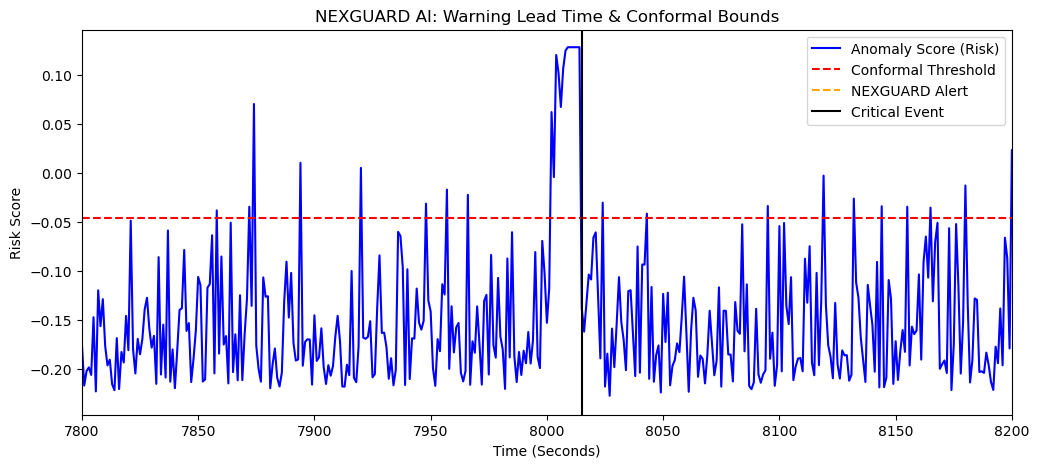

In [5]:
# --- FIX FOR RcParams._get ATTRIBUTE ERROR ---
import matplotlib
if not hasattr(matplotlib.RcParams, "_get"):
    matplotlib.RcParams._get = dict.get  # Monkey-patch the missing method

%matplotlib inline
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(df['timestamp'], df['anomaly_score'], label='Anomaly Score (Risk)', color='blue')
plt.axhline(y=conformal_threshold, color='r', linestyle='--', label='Conformal Threshold')
plt.axvline(x=first_alert_idx, color='orange', linestyle='--', label='NEXGUARD Alert')
plt.axvline(x=critical_event_idx, color='black', linestyle='-', label='Critical Event')

plt.xlim(7800, 8200)
plt.xlabel('Time (Seconds)')
plt.ylabel('Risk Score')
plt.title('NEXGUARD AI: Warning Lead Time & Conformal Bounds')
plt.legend()
plt.show()